# Proyecto Final · Modelo simple contra Random Forest
**Equipo 03:** Carlos Alberto Castro Valencia · John Alexis Cardona Zapata · Kevin Velasquez Giraldo

Ejecuciones y resultados que respaldan el documento `Proyecto_Final_IA.docx`. Variable a predecir: **`mora30`** (sí/no) → regresión logística vs Random Forest.

## 0. Carga de la base limpia

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import janitor as jn
from pathlib import Path

paleta_consultora = ['#1A365D', '#2C7A7B', '#A0AEC0', '#4FD1C5']

df = jn.clean_names(pd.read_excel(Path("DataBase") / "equipo_03_base_credito_ia_clean.xlsx"))
print("Registros:", df.shape[0], "| Columnas:", df.shape[1])
print(f"Tasa de Mora30: {df['mora30'].mean():.1%} | Tasa de Mora60: {df['mora60'].mean():.1%}")

Registros: 1208 | Columnas: 27
Tasa de Mora30: 26.3% | Tasa de Mora60: 11.7%


## 1. Verificación de fuga de información
Columnas que contienen la respuesta y no pueden usarse para predecir.

In [ ]:
mm = df["moramaxima_12_meses"]
print(f"mora30 == (moramaxima_12_meses > 30): {((mm > 30).astype(int) == df['mora30']).mean():.1%} de coincidencia")
print(f"mora60 == (moramaxima_12_meses > 60): {((mm > 60).astype(int) == df['mora60']).mean():.1%} de coincidencia")

df.groupby("semaforo_comite_riesgo").agg(
    clientes=("mora30", "size"),
    tasa_mora30=("mora30", "mean"),
    moramaxima_prom=("moramaxima_12_meses", "mean"),
    deuda_prom=("%deuda_actual_sistema_financiero", "mean"),
    score_prom=("calificacionsistema_financiero", lambda s: pd.to_numeric(s, errors="coerce").mean()),
).round(3)

mora30 == (moramaxima_12_meses > 30): 100.0% de coincidencia
mora60 == (moramaxima_12_meses > 60): 100.0% de coincidencia


,clientes,tasa_mora30,moramaxima_prom,deuda_prom,score_prom
semaforo_comite_riesgo,,,,,
ALTO,164,0.799,84.372,0.708,746.558
BAJO,1011,0.172,16.465,0.732,732.570
MEDIO,33,0.394,32.818,0.688,764.062


## 2. Preparación de los datos

In [ ]:
from sklearn.model_selection import train_test_split

objetivo = "mora30"
datos = df.copy()
datos["calificacionsistema_financiero"] = pd.to_numeric(datos["calificacionsistema_financiero"], errors="coerce")

# Id, fugas de información, fecha y columnas excluidas por el equipo
excluir = ["cliente", "mora60", "moramaxima_12_meses", "semaforo_comite_riesgo", "fdesem",
           "segmento", "sector", "regcons"]
datos = datos.drop(columns=excluir)

# Textos con demasiados valores distintos (> 20)
card = datos.drop(columns=[objetivo]).select_dtypes(exclude="number").nunique()
datos = datos.drop(columns=card[card > 20].index)
print("Valores distintos por columna de texto:", card.to_dict())

# Nulos
print("Filas con nulos eliminadas:", datos.isna().any(axis=1).sum())
datos = datos.dropna()

# Registros gemelos: mismo cliente repetido con variaciones < 1 % en ingresos, gastos y deuda
continuas = ["ingresos", "gastos", "ingresos_totales", "%deuda_actual_sistema_financiero"]
clave = [c for c in datos.columns if c not in continuas + [objetivo]]
grupo = datos.groupby(clave, dropna=False).ngroup()
print("Registros en grupos de gemelos:", (grupo.map(grupo.value_counts()) > 1).sum(), "de", len(datos))
datos = datos[~grupo.duplicated()].copy()
print("Registros finales (uno por cliente):", len(datos))

X = pd.get_dummies(datos.drop(columns=[objetivo]), drop_first=True, dtype=int)
y = datos[objetivo].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("X:", X.shape, "| entrenamiento:", X_train.shape[0], "| prueba:", X_test.shape[0])

Valores distintos por columna de texto: {'ocupacion': 2, 'tipcontrato': 6, 'estado_civil': 5, 'genero': 2, 'nivel_academico': 5, 'tipo_vivienda': 4, 'calificacion_superfinanciera': 5}
Filas con nulos eliminadas: 11
Registros en grupos de gemelos: 709 de 1197
Registros finales (uno por cliente): 790
X: (790, 33) | entrenamiento: 632 | prueba: 158


## 3. Línea base

In [ ]:
linea_base = y.value_counts(normalize=True).max()
print(f"Exactitud de decir siempre 'no mora': {linea_base:.1%}")

Exactitud de decir siempre 'no mora': 75.4%


## 4. Entrenamiento de los modelos

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

modelo_simple = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
modelo_rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
modelo_simple.fit(X_train, y_train)
modelo_rf.fit(X_train, y_train)

# Coeficientes de la regresión logística (positivo = más riesgo de mora)
coef = pd.Series(modelo_simple[-1].coef_[0], index=X.columns)
coef.reindex(coef.abs().sort_values(ascending=False).index).head(10).round(3).to_frame("coeficiente")

,coeficiente
ingresos,-1.050
gastos,-0.437
tipo_vivienda_FAMILIAR,0.419
nivel_academico_ESPECIALIZACIÓN,-0.349
calificacion_superfinanciera_E,-0.316
ingresos_totales,0.298
experiencia_financiera,-0.295
tipo_vivienda_PROPIA,0.277
genero_MASCULINO,0.253
antiguedad_en_el_sistema_financiero,-0.246


### Importancia de variables del Random Forest (top 10)

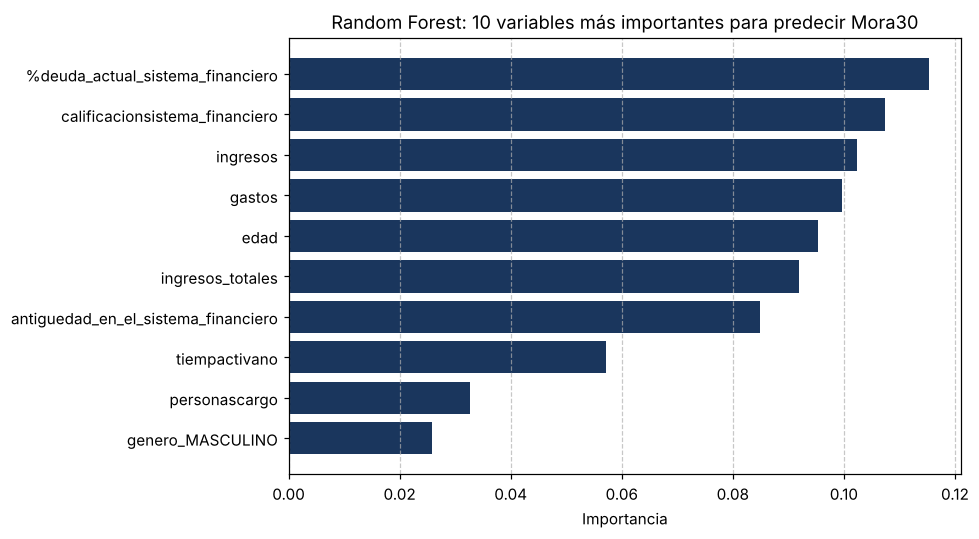

In [ ]:
top10 = pd.Series(modelo_rf.feature_importances_, index=X.columns).nlargest(10)

plt.figure(figsize=(9, 5))
plt.barh(top10.index[::-1], top10.values[::-1], color=paleta_consultora[0])
plt.title("Random Forest: 10 variables más importantes para predecir Mora30")
plt.xlabel("Importancia")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

## 5. Comparación con métricas (datos de prueba)

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

def evaluar(nombre, modelo):
    pred = modelo.predict(X_test) if modelo is not None else np.zeros(len(y_test), dtype=int)
    proba = modelo.predict_proba(X_test)[:, 1] if modelo is not None else np.zeros(len(y_test))
    return {"Modelo": nombre,
            "Exactitud": accuracy_score(y_test, pred),
            "Precisión": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "AUC": roc_auc_score(y_test, proba)}

tabla_metricas = pd.DataFrame([
    evaluar("Línea base (siempre 'no mora')", None),
    evaluar("Regresión logística", modelo_simple),
    evaluar("Random Forest", modelo_rf),
]).set_index("Modelo").round(3)
tabla_metricas

,Exactitud,Precisión,Recall,F1,AUC
Modelo,,,,,
Línea base (siempre 'no mora'),0.753,0.000,0.000,0.000,0.500
Regresión logística,0.753,0.500,0.077,0.133,0.609
Random Forest,0.766,0.625,0.128,0.213,0.638


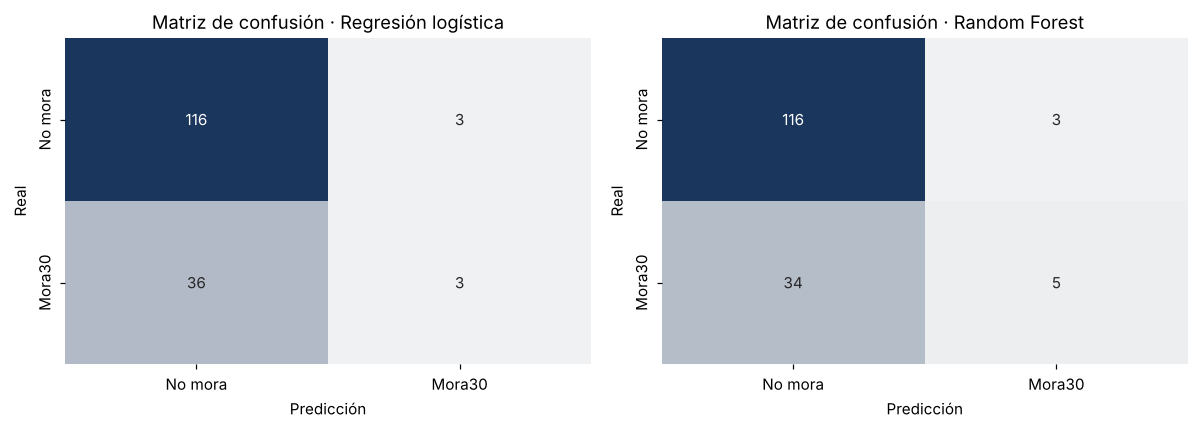

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nombre, modelo) in zip(axes, [("Regresión logística", modelo_simple), ("Random Forest", modelo_rf)]):
    mc = confusion_matrix(y_test, modelo.predict(X_test))
    sns.heatmap(mc, annot=True, fmt="d", cbar=False, ax=ax,
                cmap=sns.light_palette(paleta_consultora[0], as_cmap=True),
                xticklabels=["No mora", "Mora30"], yticklabels=["No mora", "Mora30"])
    ax.set_title(f"Matriz de confusión · {nombre}"); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

### Complementario: clases balanceadas
Solo ≈25 % de los clientes está en mora; `class_weight="balanced"` le da más peso a los morosos para detectar más casos.

In [ ]:
modelo_simple_bal = make_pipeline(StandardScaler(),
                                  LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")).fit(X_train, y_train)
modelo_rf_bal = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1,
                                       class_weight="balanced", min_samples_leaf=5).fit(X_train, y_train)

tabla_completa = pd.concat([tabla_metricas, pd.DataFrame([
    evaluar("Regresión logística (balanceada)", modelo_simple_bal),
    evaluar("Random Forest (balanceado)", modelo_rf_bal),
]).set_index("Modelo").round(3)])
tabla_completa["Morosos detectados"] = [
    f"{int(round(r * y_test.sum()))} de {int(y_test.sum())}" for r in tabla_completa["Recall"]
]
tabla_completa

,Exactitud,Precisión,Recall,F1,AUC,Morosos detectados
Modelo,,,,,,
Línea base (siempre 'no mora'),0.753,0.000,0.000,0.000,0.500,0 de 39
Regresión logística,0.753,0.500,0.077,0.133,0.609,3 de 39
Random Forest,0.766,0.625,0.128,0.213,0.638,5 de 39
Regresión logística (balanceada),0.582,0.315,0.590,0.411,0.600,23 de 39
Random Forest (balanceado),0.677,0.350,0.359,0.354,0.572,14 de 39
